# Horizontal Bar Chart (sorted)

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Bars laid out horizontally and sorted by value. Long category labels stay readable, and the sort turns the chart into a ranking as well as a size comparison.

## When to use

- Category names are long (countries, products, survey answers)
- There are many categories (up to ~25)
- Show both size and rank at once

## Avoid when

- Categories have a natural order such as time (keep that order, use columns)

## Alternatives

- Lollipop chart
- Dot plot
- Treemap (many categories)

## Design tips

- Sort descending from top; label values at bar ends and drop the x-axis if every bar is labelled

## Example

Most-used programming languages among survey respondents (% of respondents), synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
df = pd.DataFrame({
    "language": ["JavaScript", "Python", "SQL", "TypeScript", "Bash/Shell", "Java",
                 "C#", "C++", "Go", "Rust", "Kotlin", "R"],
    "pct": [62, 58, 51, 40, 33, 30, 27, 23, 14, 13, 9, 5],
}).sort_values("pct")
df.tail()

,language,pct
4,Bash/Shell,33
3,TypeScript,40
2,SQL,51
1,Python,58
0,JavaScript,62


### Plot

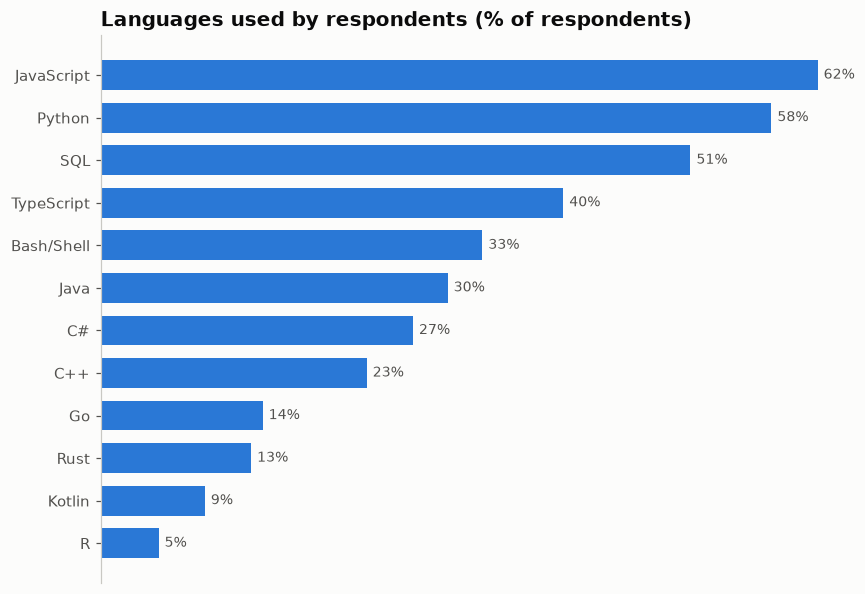

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(df["language"], df["pct"], color=PALETTE[0], height=0.7)
ax.bar_label(bars, fmt="%d%%", padding=4, fontsize=9, color="#52514e")
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.grid(False)
ax.set_title("Languages used by respondents (% of respondents)")
fig.tight_layout()
plt.show()

## How to read it

Bars are sorted from most to least used. JavaScript (62%) and Python (58%) lead, and R is last at 5%. Respondents could pick several languages, so the percentages add up to more than 100%.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.bar(df, x="pct", y="language", orientation="h", text="pct",
             color_discrete_sequence=PALETTE, title="Languages used by respondents (% of respondents)",
             labels={"pct": "% of respondents", "language": ""})
fig.update_traces(texttemplate="%{text}%", textposition="outside")
fig.update_layout(height=480)
fig.show()

### altair

In [5]:
import altair as alt
base = alt.Chart(df).encode(y=alt.Y("language:N", sort="-x", title=None),
                            x=alt.X("pct:Q", title="% of respondents"))
chart = (base.mark_bar(color=PALETTE[0], cornerRadiusEnd=3)
         + base.mark_text(align="left", dx=4, color="#52514e").encode(text=alt.Text("pct:Q", format=".0f"))
         ).properties(title="Languages used by respondents (% of respondents)", width=460, height=340)
chart

alt.LayerChart(...)

---
Standalone script: [`horizontal_bar.py`](horizontal_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)